In [ ]:
#Question 1

In [ ]:
in a dilute liquid-phase reactor the reaction A+B revercible c reaches equilibrium. initial concentrations are [A]=0.5 and [C]=0 mol/L of C is formed,Kc=x/(0.5-x)power2 , which rearranges to the quadratic equation      Kc*xsquare - (Kc+1)*x + 0.25*Kc =0        wrute a python program that :                 (a) reads Kc using input(), print the data type of the raw input and of the converted value, and shows a clear message (no crash ) if the text is not a number or if Kc<=0;

In [10]:
import math
raw_kc = input("Enter the equilibrium constant Kc: ")
print(f"Raw input type: {type(raw_kc).__name__}")
try:
    kc = float(raw_kc)
    print(f"Converted value type: {type(kc).__name__}")
except ValueError:
    print("Invalid input: Kc must be a number.")
else:
    if not math.isfinite(kc) or kc <= 0:
        print("Invalid input: Kc must be a positive number.")
    else:
        a = kc
        b = -(kc + 1)
        c = 0.25 * kc
        discriminant = b**2 - 4 * a * c

        roots = [
            (-b + math.sqrt(discriminant)) / (2 * a),
            (-b - math.sqrt(discriminant)) / (2 * a),
        ]
        valid_roots = [root for root in roots if 0 <= root < 0.5]

        print(f"Kc = {kc}")
        print(f"Physically valid equilibrium concentration, x = {valid_roots[0]:.6f} mol/L")

Raw input type: str
Converted value type: float
Kc = 6.0
Physically valid equilibrium concentration, x = 0.282871 mol/L


In [ ]:
 (b) finds a,b,c, the discriminant and both roots;

In [11]:
print(f"a = {a}")
print(f"b = {b}")
print(f"c = {c}")
print(f"Discriminant = {discriminant}")

print(f"Root 1 (x1) = {roots[0]:.6f}")
print(f"Root 2 (x2) = {roots[1]:.6f}")

a = 6.0
b = -7.0
c = 1.5
Discriminant = 13.0
Root 1 (x1) = 0.883796
Root 2 (x2) = 0.282871


In [ ]:
(c) selects the physicallu meaningful root (0<= x <= 0.5)

In [12]:
valid_roots = [root for root in roots if 0 <= root <= 0.5]

if valid_roots:
    x = valid_roots[0]
    print(f"Physically meaningful root: x = {x:.6f} mol/L")
else:
    print("No physically meaningful root exists in the range 0 <= x <= 0.5.")

Physically meaningful root: x = 0.282871 mol/L


In [ ]:
(d) print equilibrium [A],[B],[C] (3decimals) and the conversion of the limiting reactant = x/[A]*100(%)

In [13]:
initial_A = 0.5
initial_B = 0.5

equilibrium_A = initial_A - x
equilibrium_B = initial_B - x
equilibrium_C = x

conversion = (x / initial_A) * 100

print(f"[A]_eq = {equilibrium_A:.3f} mol/L")
print(f"[B]_eq = {equilibrium_B:.3f} mol/L")
print(f"[C]_eq = {equilibrium_C:.3f} mol/L")
print(f"Conversion of limiting reactant = {conversion:.3f}%")

[A]_eq = 0.217 mol/L
[B]_eq = 0.217 mol/L
[C]_eq = 0.283 mol/L
Conversion of limiting reactant = 56.574%


In [ ]:
(e) classifies the conversion using if / elif / else: >=70 % "High" ,  >= 40% "moderate" , otherwise "low".

In [14]:
if conversion >= 70:
    conversion_class = "High"
elif conversion >= 40:
    conversion_class = "moderate"
else:
    conversion_class = "low"

print(f"Conversion classification: {conversion_class}")

Conversion classification: moderate


In [ ]:
# question 2 

In [ ]:
Part A. A pollution in wastewater is degraded in a batch photoreactor by a first-order reaction, dc/dt = -kc. use the euler method : C_new = C_old - k*C_old*delta t. take c=1.0 mol/L, k=0.12min inverse , delta t = 0.5 min.     (1) using a for loop, simultate 5 minutes and print a table of time(min), concentration (mol/L) and conversion (%).

In [18]:
C_initial = 1.0
C = C_initial
k = 0.12
delta_t = 0.5

print(f"{'Time (min)':>12} {'Concentration (mol/L)':>24} {'Conversion (%)':>16}")

time = 0.0
conversion = (C_initial - C) / C_initial * 100
print(f"{time:>12.1f} {C:>24.4f} {conversion:>16.2f}")

for step in range(int(5 / delta_t)):
    C = C - k * C * delta_t
    time += delta_t
    conversion = (C_initial - C) / C_initial * 100

    print(f"{time:>12.1f} {C:>24.4f} {conversion:>16.2f}")

  Time (min)    Concentration (mol/L)   Conversion (%)
         0.0                   1.0000             0.00
         0.5                   0.9400             6.00
         1.0                   0.8836            11.64
         1.5                   0.8306            16.94
         2.0                   0.7807            21.93
         2.5                   0.7339            26.61
         3.0                   0.6899            31.01
         3.5                   0.6485            35.15
         4.0                   0.6096            39.04
         4.5                   0.5730            42.70
         5.0                   0.5386            46.14


In [ ]:
(2) using math.exp(), calculate the exact value Ce to the power (-kt) at 5 min and print the absolute error of the euler result.

In [19]:
import math

C_exact = C_initial * math.exp(-k * 5)
absolute_error = abs(C - C_exact)

print(f"Exact concentration at 5 min = {C_exact:.4f} mol/L")
print(f"Euler concentration at 5 min = {C:.4f} mol/L")
print(f"Absolute error = {absolute_error:.4f} mol/L")

Exact concentration at 5 min = 0.5488 mol/L
Euler concentration at 5 min = 0.5386 mol/L
Absolute error = 0.0102 mol/L


In [ ]:
(3)using a while loop , repeat the simulation unitil conversion reaches 70 % or time reaches 100 min. print the time needed and the final concentration.

In [20]:
C_initial = 1.0
C = C_initial
k = 0.12
delta_t = 0.5
time = 0.0

conversion = (C_initial - C) / C_initial * 100

while conversion < 70 and time < 100:
    C = C - k * C * delta_t
    time += delta_t
    conversion = (C_initial - C) / C_initial * 100

print(f"Time needed = {time:.1f} min")
print(f"Final concentration = {C:.4f} mol/L")
print(f"Final conversion = {conversion:.2f}%")

Time needed = 10.0 min
Final concentration = 0.2901 mol/L
Final conversion = 70.99%


In [ ]:
Part B. storage tank lots such as TK0045-LOT19 are stored as text. write a program that reads a lot code, loops through rach cgaracter, and prints the number of digits and sum of the digits. show a meesage for an empty code and for a code with no digits. test with TK0045-LOT19 , an empty code and ABCDEF.

In [21]:
def analyze_lot_code(code):
    if code == "":
        print("Lot code cannot be empty.")
        return

    digit_count = 0
    digit_sum = 0

    for character in code:
        if character.isdigit():
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print("Lot code contains no digits.")
    else:
        print(f"Number of digits: {digit_count}")
        print(f"Sum of digits: {digit_sum}")


lot_codes = ["TK0045-LOT19", "", "ABCDEF"]

for lot in lot_codes:
    print(f"\nLot code: {lot}")
    analyze_lot_code(lot)


Lot code: TK0045-LOT19
Number of digits: 6
Sum of digits: 19

Lot code: 
Lot code cannot be empty.

Lot code: ABCDEF
Lot code contains no digits.


In [ ]:
#Question 3

In [ ]:
Part A. a plant has n candidate feed components and wants to blend r of them (order does not matter). write a recursive function factorial(n) (remember the base case for 0 factorial) and a function combination (n,r)=n factorial/(r factorial(n-r)factorial) that uses it reject invalid input (negative values, r>n). print the number of possible blends for n=8 r=4, and show the message for n=3, r=5.

In [22]:
def factorial(n):
    if n == 0 or n == 1:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0:
        print("Invalid input: n and r must be non-negative.")
        return None

    if r > n:
        print("Invalid input: r cannot be greater than n.")
        return None

    return factorial(n) // (factorial(r) * factorial(n - r))


print(f"Number of blends: {combination(8, 4)}")
combination(3, 5)

Number of blends: 70
Invalid input: r cannot be greater than n.


In [ ]:
Part B. during a cooling experiment, temperature readings are taken at times = fibonacci number*3 min. write an iterative funtion fib_iter(n) that returns a list of the first n fibonacci number , and a recursive function fib_rec(k) that returns the k-th fibonacci (f0=0 , f1=1 ). for n=8, check that both function agree and print a table: reading no. | fibonacci tag | time (min).

In [ ]:
def fib_iter(n):
    numbers = []

    for i in range(n):
        if i == 0:
            numbers.append(0)
        elif i == 1:
            numbers.append(1)
        else:
            numbers.append(numbers[i - 1] + numbers[i - 2])

    return numbers


def fib_rec(k):
    if k == 0:
        return 0
    if k == 1:
        return 1

    return fib_rec(k - 1) + fib_rec(k - 2)


n = 8
iterative_values = fib_iter(n)
recursive_values = [fib_rec(i) for i in range(n)]

if iterative_values == recursive_values:
    print("Both functions agree.")
else:
    print("The functions do not agree.")

print(f"{'Reading No.':>12} {'Fibonacci Tag':>15} {'Time (min)':>12}")
for reading_no, fibonacci_tag in enumerate(iterative_values, start=1):
    time = fibonacci_tag * 3
    print(f"{reading_no:>12} {fibonacci_tag:>15} {time:>12}")

Both functions agree.
 Reading No.   Fibonacci Tag   Time (min)
           1               0            0
           2               1            3
           3               1            3
           4               2            6
           5               3            9
           6               5           15
           7               8           24
           8              13           39


In [ ]:
#Question 4

In [ ]:
photocatalytic degradation of a dye was studied at two UV intensities. the concentration (mol/L) was recorded:     Time_min = 1,10,20,30,40,50                 Run1_mol_L (low UV) = 0.80,0.54,0.36,0.24,0.16,0.11          Run2_mol_L (high UV) = 0.80,0.44,0.24,0.13,0.07,0.04                       (a) create a DataFrame from this table. save it as Kinetics . csv (without the index column) and as Kinetics . json. read the CSV back and print its shape and data types.

In [ ]:
import pandas as pd

data = {
    "Time_min": [1, 10, 20, 30, 40, 50],
    "Run1_mol_L": [0.80, 0.54, 0.36, 0.24, 0.16, 0.11],
    "Run2_mol_L": [0.80, 0.44, 0.24, 0.13, 0.07, 0.04]
}

kinetics_df = pd.DataFrame(data)

kinetics_df.to_csv("Kinetics.csv", index=False)
kinetics_df.to_json("Kinetics.json", orient="records")

loaded_df = pd.read_csv("Kinetics.csv")

print("Shape:", loaded_df.shape)
print("\nData types:")
print(loaded_df.dtypes)

Shape: (6, 3)

Data types:
Time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object


In [ ]:
(b) print the mean and standard deviation of Run1 and Run2, and state which run shows more variation

In [ ]:
mean_run1 = kinetics_df["Run1_mol_L"].mean()
std_run1 = kinetics_df["Run1_mol_L"].std()

mean_run2 = kinetics_df["Run2_mol_L"].mean()
std_run2 = kinetics_df["Run2_mol_L"].std()

print(f"Run1 mean: {mean_run1:.4f} mol/L")
print(f"Run1 standard deviation: {std_run1:.4f} mol/L")
print(f"Run2 mean: {mean_run2:.4f} mol/L")
print(f"Run2 standard deviation: {std_run2:.4f} mol/L")

if std_run1 > std_run2:
    print("Run1 shows more variation.")
elif std_run2 > std_run1:
    print("Run2 shows more variation.")
else:
    print("Both runs show equal variation.")

Run1 mean: 0.3683 mol/L
Run1 standard deviation: 0.2617 mol/L
Run2 mean: 0.2867 mol/L
Run2 standard deviation: 0.2904 mol/L
Run2 shows more variation.


In [ ]:
(c) plot both runs on one graph (Time on x-axis) with title, axis labels with units, legend and grid.

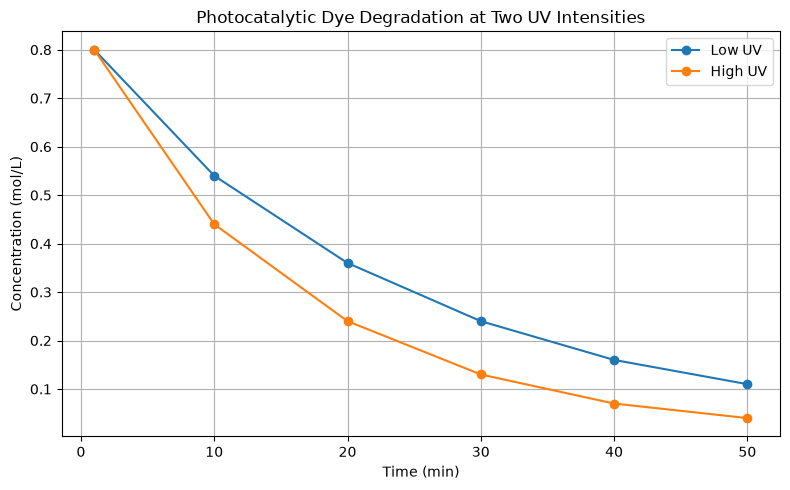

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    kinetics_df["Time_min"],
    kinetics_df["Run1_mol_L"],
    marker="o",
    label="Low UV"
)

plt.plot(
    kinetics_df["Time_min"],
    kinetics_df["Run2_mol_L"],
    marker="o",
    label="High UV"
)

plt.title("Photocatalytic Dye Degradation at Two UV Intensities")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
(d) air is compressed slowly in a piston-cylinder vessel at constant temperature: Volume_L = 2,3,4,5,6                      Pressure_bar = 3.01,1.98,1.52,1.19,1.01   plot pressure vs. volume as a scatter plot. calculate k as the mean of P*V and draw the reference curve P=k/V on the same graph. Add title, lables with units and legend.

k = 6.010 bar·L


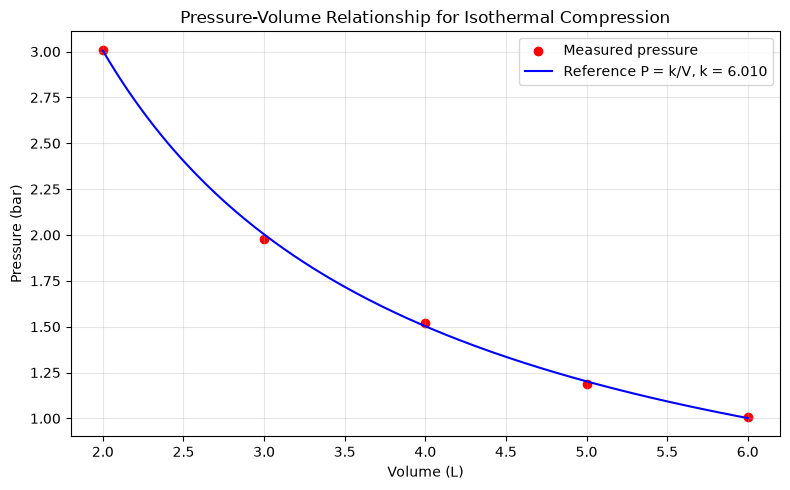

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

volume = np.array([2, 3, 4, 5, 6])
pressure = np.array([3.01, 1.98, 1.52, 1.19, 1.01])

k = np.mean(pressure * volume)
print(f"k = {k:.3f} bar·L")

volume_curve = np.linspace(volume.min(), volume.max(), 200)
pressure_curve = k / volume_curve

plt.figure(figsize=(8, 5))
plt.scatter(volume, pressure, color="red", label="Measured pressure")
plt.plot(volume_curve, pressure_curve, color="blue", label=f"Reference P = k/V, k = {k:.3f}")

plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.title("Pressure-Volume Relationship for Isothermal Compression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()